# Lesson 11: Linear Regression with Multiple Regressors
**ECON 5105 · Mathematics and Statistics for Economists · Fall 2026**

A runnable companion to Qianwei Shen's *Lesson 11* (November 19, 2026).

**Question:** How does the relationship between student-teacher ratio and test scores change when we hold district characteristics constant?

All observations in this notebook are **simulated**. The school example is inspired by the slides; estimates are not empirical California results. Seeds make results reproducible. No external files or downloads are required after package installation.

**Setup:** Python 3.10+ with `numpy pandas matplotlib scipy statsmodels scikit-learn ipykernel`. If needed, run `%pip install numpy pandas matplotlib scipy statsmodels scikit-learn ipykernel` in a new cell. Select a Python kernel and **Restart Kernel and Run All**. Saved outputs let you preview the notebook on GitHub.

## Road map
1. Multiple regression and coefficient interpretation (slides 4–9, 56)
2. Omitted-variable bias and appropriate controls (slides 12–38)
3. Fit measures and inference (slides 10–11, 39–41)
4. Perfect and imperfect multicollinearity, dummy variables, and VIF (slides 34–47)
5. Regression diagnostics (slide 55)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from IPython.display import display
from statsmodels.stats.outliers_influence import variance_inflation_factor

SEED = 5119
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'figure.dpi': 100,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.options.display.float_format = '{:,.3f}'.format

def design(frame, columns):
    return sm.add_constant(frame[columns], has_constant='add')

Matplotlib is building the font cache; this may take a moment.


## 1. Multiple regression: one outcome, several regressors
$$TestScore_i=\beta_0+\beta_1 STR_i+\beta_2 PctEL_i+\beta_3 LchPct_i+u_i.$$
`PctEL` is percent English learners; `LchPct` is percent eligible for subsidized lunch. Percentages are measured on a **0–100 scale**: one unit is one percentage point.

We generate correlated district characteristics and independent mean-zero errors. In this constructed population the STR coefficient is **−1.10**, holding both other variables fixed. We assign this causal structure for teaching; observational school data would require a substantive identification argument.

In [2]:
rng = np.random.default_rng(SEED)
n = 600
pct_el = rng.uniform(0, 60, n)
lunch_pct = np.clip(15 + .65*pct_el + rng.normal(0, 12, n), 0, 100)
str_values = 16 + .055*pct_el + .025*lunch_pct + rng.normal(0, 1.5, n)
true_beta = np.array([710., -1.10, -.650, -.350])
df = pd.DataFrame({'STR': str_values, 'PctEL': pct_el, 'LchPct': lunch_pct})
errors = rng.normal(0, 9, n)
df['TestScore'] = design(df, ['STR', 'PctEL', 'LchPct']).to_numpy() @ true_beta + errors
predictors = ['STR', 'PctEL', 'LchPct']
full = sm.OLS(df.TestScore, design(df, predictors)).fit()
short = sm.OLS(df.TestScore, design(df, ['STR'])).fit()
two = sm.OLS(df.TestScore, design(df, ['STR', 'PctEL'])).fit()
display(df.head())
display(df.describe())
display(pd.DataFrame({'Population': true_beta, 'Estimated': full.params.to_numpy()},
                     index=['const']+predictors))

,STR,PctEL,LchPct,TestScore
0,19.336,29.712,35.120,653.612
1,15.450,1.624,5.349,684.889
2,17.105,25.713,35.550,664.211
3,19.694,32.506,27.331,660.742
4,15.672,30.358,39.638,662.093


,STR,PctEL,LchPct,TestScore
count,600.000,600.000,600.000,600.000
mean,18.501,30.984,34.870,657.333
std,1.905,17.287,16.269,19.305
min,11.499,0.086,0.000,603.272
25%,17.151,15.544,24.190,643.245
50%,18.477,31.977,34.370,656.833
75%,19.808,46.339,46.265,672.001
max,24.347,59.997,83.899,707.335


,Population,Estimated
const,710.000,713.988
STR,-1.100,-1.288
PctEL,-0.650,-0.615
LchPct,-0.350,-0.395


### OLS in matrix form
$$\hat\beta=(X'X)^{-1}X'Y.$$
Here $X$ has an intercept column plus three regressor columns. The formula requires full column rank. In code, `lstsq` avoids explicitly forming an inverse and is generally numerically preferable.

A one-unit change in STR changes the fitted score by $\hat\beta_1$ **holding PctEL and LchPct fixed**. A coefficient on a control is not automatically its causal effect.

Design dimensions: (600, 4); rank: 4


,STR,PctEL,LchPct,Fitted score
0,20.000,25.000,40.000,657.054
1,19.000,25.000,40.000,658.341


Predicted score change for STR 20 → 19: 1.288


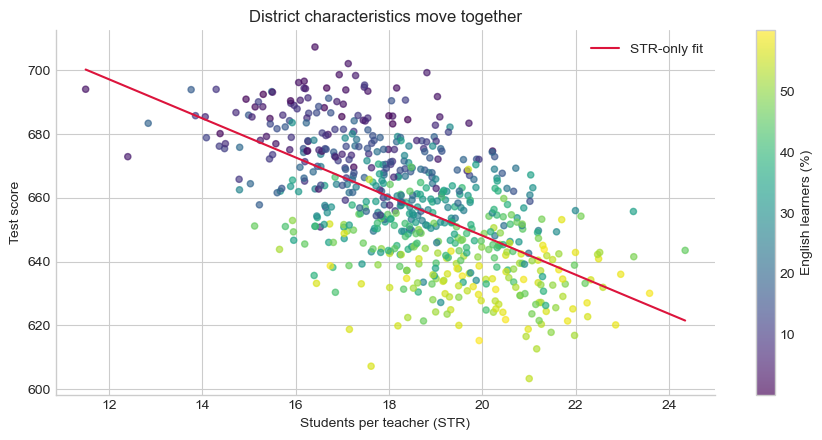

In [3]:
X = design(df, predictors)
matrix_beta = np.linalg.lstsq(X.to_numpy(), df.TestScore.to_numpy(), rcond=None)[0]
np.testing.assert_allclose(matrix_beta, full.params, rtol=1e-10)
np.testing.assert_allclose(X.to_numpy().T @ full.resid, 0, atol=1e-7)
print(f'Design dimensions: {X.shape}; rank: {np.linalg.matrix_rank(X)}')
comparison = pd.DataFrame({'STR': [20., 19.], 'PctEL': [25., 25.], 'LchPct': [40., 40.]})
comparison['Fitted score'] = full.predict(design(comparison, predictors))
display(comparison)
print(f'Predicted score change for STR 20 → 19: {-full.params["STR"]:.3f}')
fig, ax = plt.subplots()
sc = ax.scatter(df.STR, df.TestScore, c=df.PctEL, cmap='viridis', s=20, alpha=.65)
grid = np.linspace(df.STR.min(), df.STR.max(), 100)
ax.plot(grid, short.params['const']+short.params['STR']*grid, color='crimson', label='STR-only fit')
ax.set(xlabel='Students per teacher (STR)', ylabel='Test score', title='District characteristics move together')
ax.legend(); fig.colorbar(sc, ax=ax, label='English learners (%)'); plt.tight_layout(); plt.show()

## 2. Omitted-variable bias and controls
An omitted variable creates bias in the coefficient on $X$ when it **affects the outcome** and **is correlated with $X$**. In a two-regressor population model,
$$\operatorname{plim}\hat b_{1,short}=\beta_1+\beta_2\frac{\operatorname{Cov}(X,Z)}{\operatorname{Var}(X)}.$$

In our example both PctEL and LchPct are omitted from the STR-only fit. We can verify an **exact sample identity** using coefficients from the full regression:
$$\hat b_{STR,short}=\hat b_{STR,full}+\hat b_{EL,full}\hat\delta_{EL}+\hat b_{lunch,full}\hat\delta_{lunch},$$
where each $\hat\delta$ is the slope from regressing that omitted variable on STR. This identity describes the coefficient change; by itself it does not establish causality.

In [4]:
delta_el = sm.OLS(df.PctEL, design(df, ['STR'])).fit().params['STR']
delta_lunch = sm.OLS(df.LchPct, design(df, ['STR'])).fit().params['STR']
contributions = pd.Series({
    'Full-model STR coefficient': full.params['STR'],
    'PctEL omission contribution': full.params['PctEL']*delta_el,
    'LchPct omission contribution': full.params['LchPct']*delta_lunch,
})
np.testing.assert_allclose(contributions.sum(), short.params['STR'], atol=1e-10)
display(contributions.to_frame('Sample decomposition'))
print(f'Sum = {contributions.sum():.3f}; STR-only slope = {short.params["STR"]:.3f}')
display(pd.DataFrame({'STR only': short.params, '+ PctEL': two.params,
                      '+ PctEL + LchPct': full.params}))

,Sample decomposition
Full-model STR coefficient,-1.288
PctEL omission contribution,-3.273
LchPct omission contribution,-1.571


Sum = -6.132; STR-only slope = -6.132


,STR only,+ PctEL,+ PctEL + LchPct
LchPct,NaN,NaN,-0.395
PctEL,NaN,-0.832,-0.615
STR,-6.132,-1.703,-1.288
const,770.774,714.615,713.988


### Which controls belong in the regression?
The simulated causal graph includes `PctEL → STR`, `PctEL → TestScore`, `LchPct → STR`, `LchPct → TestScore`, and `STR → TestScore`. Conditioning on these pre-treatment confounders blocks the corresponding backdoor paths.

For the fully specified model we imposed $E(u\mid STR,PctEL,LchPct)=0$. Conditional mean independence of the treatment error given controls is an identification assumption, not something a high R² proves. The weaker statement $E(u\mid X,W)=E(u\mid W)$ can identify a treatment effect when the dependence on $W$ is modeled appropriately; simply adding one linear term for an arbitrary $W$ does not guarantee adequate adjustment.

Choose controls using theory, timing, and a causal graph. Conditioning on a mediator can remove part of a total effect; conditioning on a collider can create bias. A changed STR coefficient is a clue to investigate, not a proof that the larger model identifies the causal effect.

**Slide 8 arithmetic:** The lecture's empirical STR coefficient changes from −2.28 to −1.10 after adding PctEL. That is a decrease in **absolute magnitude**; numerically, the coefficient rises toward zero. Our simulated coefficients need not match those values.

## 3. Fit measures and inference
For $k$ regressors **excluding the intercept**,
$$R^2=1-\frac{RSS}{TSS},\qquad \bar R^2=1-\frac{RSS/(n-k-1)}{TSS/(n-1)},$$
$$SER=\sqrt{\frac{RSS}{n-k-1}},\qquad RMSE=\sqrt{\frac{RSS}{n}}.$$
All models below use the same observations and an intercept. Adding regressors cannot reduce training R², but adjusted R² can fall. Better fit does not identify a causal effect.

In [5]:
def fit_measures(fit):
    sample_n = int(fit.nobs)
    k = int(fit.df_model)
    rss = np.sum(fit.resid**2)
    tss = np.sum((fit.model.endog-fit.model.endog.mean())**2)
    adjusted = 1-(rss/(sample_n-k-1))/(tss/(sample_n-1))
    np.testing.assert_allclose(adjusted, fit.rsquared_adj)
    return {'n': sample_n, 'k': k, 'R²': fit.rsquared, 'Adjusted R²': adjusted,
            'SER': np.sqrt(rss/(sample_n-k-1)), 'Training RMSE': np.sqrt(rss/sample_n)}
fit_table = pd.DataFrame({name: fit_measures(fit) for name, fit in
                         [('STR only', short), ('+ PctEL', two), ('+ PctEL + LchPct', full)]}).T
assert short.rsquared <= two.rsquared + 1e-12 <= full.rsquared + 2e-12
display(fit_table)
print(full.summary())

,n,k,R²,Adjusted R²,SER,Training RMSE
STR only,600.000,1.000,0.366,0.365,15.384,15.359
+ PctEL,600.000,2.000,0.730,0.729,10.051,10.026
+ PctEL + LchPct,600.000,3.000,0.792,0.791,8.826,8.797


                            OLS Regression Results                            
Dep. Variable:              TestScore   R-squared:                       0.792
Model:                            OLS   Adj. R-squared:                  0.791
Method:                 Least Squares   F-statistic:                     756.6
Date:                Thu, 19 Nov 2026   Prob (F-statistic):          1.02e-202
Time:                        11:34:56   Log-Likelihood:                -2156.0
No. Observations:                 600   AIC:                             4320.
Df Residuals:                     596   BIC:                             4338.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        713.9881      3.928    181.786      0.0

### Testing one coefficient and constructing a confidence interval
For $H_0:\beta_j=\beta_{j,0}$, compute $(\hat\beta_j-\beta_{j,0})/SE(\hat\beta_j)$.

We report **HC1 heteroskedasticity-robust standard errors with a large-sample normal reference distribution**. The exact finite-sample Student t result requires stronger assumptions, including normally distributed homoskedastic errors; the basic least-squares assumptions alone do not give an exact t distribution. Robust standard errors do not repair omitted variables, a misspecified conditional mean, or dependent observations.

In [6]:
robust = full.get_robustcov_results(cov_type='HC1', use_t=False)
names = full.model.exog_names
coef_table = pd.DataFrame({'Coefficient': robust.params, 'HC1 SE': robust.bse,
                          'z': robust.tvalues, 'p-value': robust.pvalues,
                          '95% lower': robust.conf_int()[:, 0],
                          '95% upper': robust.conf_int()[:, 1]}, index=names)
display(coef_table)
j = names.index('STR')
null_slope = 0.
z = (robust.params[j]-null_slope)/robust.bse[j]
pvalue = 2*stats.norm.sf(abs(z))
np.testing.assert_allclose(pvalue, robust.pvalues[j])
print(f'H0: STR coefficient = {null_slope:.1f}; z = {z:.3f}; p = {pvalue:.4g}')
print('Interpret the STR estimate conditional on both included controls.')

,Coefficient,HC1 SE,z,p-value,95% lower,95% upper
const,713.988,3.938,181.306,0.000,706.270,721.706
STR,-1.288,0.236,-5.460,0.000,-1.750,-0.825
PctEL,-0.615,0.031,-20.052,0.000,-0.675,-0.555
LchPct,-0.395,0.029,-13.574,0.000,-0.452,-0.338


H0: STR coefficient = 0.0; z = -5.460; p = 4.75e-08
Interpret the STR estimate conditional on both included controls.


## 4. Multicollinearity: perfect versus imperfect
**Perfect:** One column is an exact linear combination of others. Coefficients are not uniquely identified. Some software uses a pseudoinverse and still returns output, so do not rely on it raising an error.

**Imperfect:** Columns are highly related, but full rank remains. OLS can still be unbiased under exogeneity, with less precision for individual coefficients.

### The dummy-variable trap
All mutually exclusive, exhaustive group indicators sum to one. With an intercept, omit one reference category. Without an intercept, retaining every group indicator instead yields a separate group intercept.

In [7]:
group_rng = np.random.default_rng(SEED+1)
groups = pd.Series(group_rng.choice(['North', 'South', 'West'], size=n), name='Region')
dummies = pd.get_dummies(groups, dtype=float)
trapped = sm.add_constant(dummies, has_constant='add')
reference_design = sm.add_constant(dummies.drop(columns='North'), has_constant='add')
print(f'All dummies + intercept: {trapped.shape[1]} columns, rank {np.linalg.matrix_rank(trapped)}')
print(f'Reference coding:       {reference_design.shape[1]} columns, rank {np.linalg.matrix_rank(reference_design)}')
assert np.linalg.matrix_rank(trapped) < trapped.shape[1]
assert np.linalg.matrix_rank(reference_design) == reference_design.shape[1]
reference_fit = sm.OLS(df.TestScore, reference_design).fit()
no_intercept_fit = sm.OLS(df.TestScore, dummies).fit()
np.testing.assert_allclose(reference_fit.fittedvalues, no_intercept_fit.fittedvalues)
display(pd.DataFrame({'Group mean (no intercept)': no_intercept_fit.params,
                      'Observed group mean': df.TestScore.groupby(groups).mean()}))
print('Reference-model intercept = North mean; South/West coefficients = differences from North.')

All dummies + intercept: 4 columns, rank 3
Reference coding:       3 columns, rank 3


,Group mean (no intercept),Observed group mean
North,656.756,656.756
South,658.091,658.091
West,657.130,657.130


Reference-model intercept = North mean; South/West coefficients = differences from North.


### Correlations and variance inflation factors
$$VIF_j=\frac{1}{1-R_j^2},$$
where $R_j^2$ comes from regressing predictor $j$ on all other predictors and an intercept. VIF concerns a predictor's relationship to **all** the others; a pairwise correlation matrix can miss multi-variable dependence. Thresholds such as 5 or 10 are heuristics, not automatic deletion rules.

**Reading the results below:** In this simulated sample, the largest absolute pairwise correlation among the original predictors is about 0.655 (PctEL and LchPct). Their VIFs range from 1.55 to 2.13, so these checks do not suggest severe multicollinearity. Adding the artificial STR near-copy produces VIFs above 590 for the two STR variables and sharply increases their standard errors. The near-copy is a teaching demonstration, not part of the original school model.

In [8]:
def vif_table(frame):
    exog = sm.add_constant(frame, has_constant='add').to_numpy(dtype=float)
    return pd.Series({name: variance_inflation_factor(exog, j+1)
                      for j, name in enumerate(frame.columns)}, name='VIF')
display(df[predictors].corr())
display(vif_table(df[predictors]).to_frame())
col_rng = np.random.default_rng(SEED+2)
collinear_df = df[predictors].copy()
collinear_df['STR_near_copy'] = df.STR + col_rng.normal(0, .08, n)
unstable = sm.OLS(df.TestScore, sm.add_constant(collinear_df)).fit()
display(vif_table(collinear_df).to_frame())
display(pd.DataFrame({'Original coefficient': full.params, 'With near copy': unstable.params,
                      'Original SE': full.bse, 'With near copy SE': unstable.bse}))
print('A redundant near-copy adds little information while making the separate STR slopes imprecise.')

,STR,PctEL,LchPct
STR,1.000,0.587,0.465
PctEL,0.587,1.000,0.655
LchPct,0.465,0.655,1.000


,VIF
STR,1.552
PctEL,2.132
LchPct,1.784


,VIF
STR,595.213
PctEL,2.139
LchPct,1.785
STR_near_copy,592.779


,Original coefficient,With near copy,Original SE,With near copy SE
LchPct,-0.395,-0.396,0.030,0.030
PctEL,-0.615,-0.614,0.030,0.031
STR,-1.288,-3.428,0.236,4.622
STR_near_copy,NaN,2.134,NaN,4.603
const,713.988,714.073,3.928,3.934


A redundant near-copy adds little information while making the separate STR slopes imprecise.


## 5. Diagnostics: look at what the line leaves unexplained
Residual-versus-fitted plots can reveal changing variance or a missing nonlinear pattern. A Q–Q plot helps inspect tail behavior; normal residuals are not a prerequisite for large-sample robust inference.

Below we generate mean-zero errors whose variance rises with PctEL. HC1 addresses heteroskedasticity in standard-error estimation, but does not correct a wrong mean function, dependence, or confounding. No residual plot proves causal identification.

,Coefficient,Conventional SE,HC1 SE
const,710.350,6.751,6.457
STR,-1.227,0.405,0.383
PctEL,-0.687,0.052,0.054
LchPct,-0.242,0.051,0.051


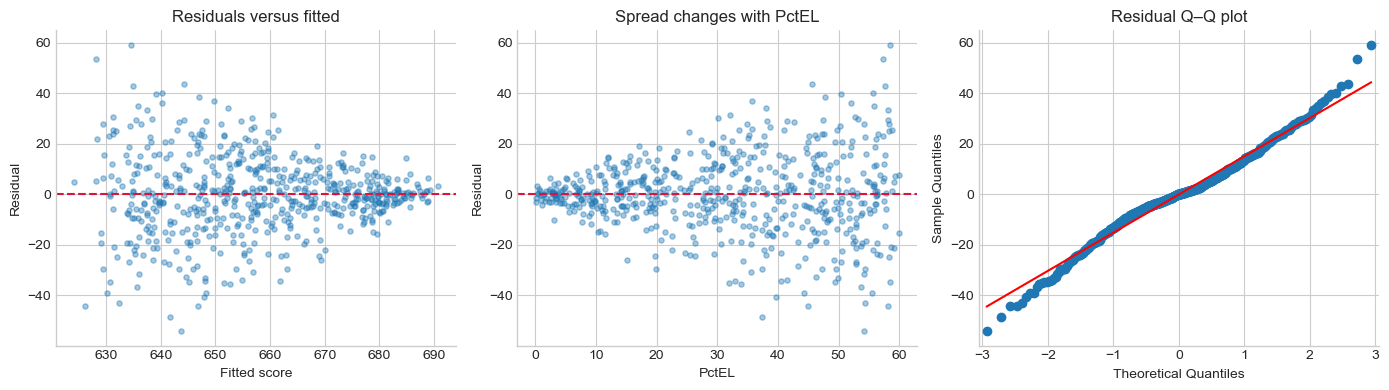

In [9]:
diag_rng = np.random.default_rng(SEED+3)
y_het = X.to_numpy() @ true_beta + diag_rng.normal(0, 3+.35*df.PctEL.to_numpy(), n)
hetero = sm.OLS(y_het, X).fit()
hetero_robust = hetero.get_robustcov_results(cov_type='HC1', use_t=False)
display(pd.DataFrame({'Coefficient': hetero.params, 'Conventional SE': hetero.bse,
                      'HC1 SE': hetero_robust.bse}))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(hetero.fittedvalues, hetero.resid, alpha=.4, s=14)
axes[0].axhline(0, color='crimson', linestyle='--')
axes[0].set(xlabel='Fitted score', ylabel='Residual', title='Residuals versus fitted')
axes[1].scatter(df.PctEL, hetero.resid, alpha=.4, s=14)
axes[1].axhline(0, color='crimson', linestyle='--')
axes[1].set(xlabel='PctEL', ylabel='Residual', title='Spread changes with PctEL')
sm.qqplot(hetero.resid, line='s', ax=axes[2])
axes[2].set_title('Residual Q–Q plot')
plt.tight_layout(); plt.show()

## Try it yourself
1. Set the population PctEL coefficient to zero. Does the STR-only model still omit a relevant variable correlated with STR?
2. Add an independent random predictor. Must both R² and adjusted R² increase?
3. Reduce the noise in `STR_near_copy` from 0.08 to 0.02. What happens to VIF and the separate STR standard errors?
4. Why might a pairwise correlation matrix miss multicollinearity involving several predictors?
5. Compare conventional and HC1 standard errors in the heteroskedasticity example. Do the fitted coefficients change?

### Discussion notes
1. Yes: LchPct still affects scores and is correlated with STR.
2. With the same sample and an intercept, training R² cannot fall; adjusted R² can fall.
3. VIF generally increases and separating the two STR slopes becomes harder.
4. One predictor may be nearly a linear combination of several others even when no pair has an extreme correlation. VIF uses all other predictors jointly.
5. HC1 changes the estimated uncertainty, not OLS coefficients or fitted values. It does not fix omitted-variable bias.

**Source:** Qianwei Shen, *ECON 5105, Lesson 11: Linear Regression with Multiple Regressors*, November 19, 2026, slides 1–58. The notebook supplies original simulated data and demonstrations rather than reproducing the lecture PDF or empirical school records.